# Artificial light reorients nocturnal dung beetles

We revisit and re-analyze the two-condition arena experiment in nocturnal ball-rolling dung beetles (*Escarabaeus satyrus*) of J. J. Foster et al., "Light pollution forces a change in dung beetle orientation behavior," *Current Biology* **31**(17), 3935-3942 (2021); [doi:10.1016/j.cub.2021.06.038](https://doi.org/10.1016/j.cub.2021.06.038): each beetle is placed at the center of a circular arena and allowed to roll to the boundary, and its exit bearing is recorded repeatedly under natural nighttime illumination (control) and with an artificial floodlight switched on (treatment).

This notebook fits the hierarchical von Mises model of the study with `brms` and the
`unwrap_von_mises` family. `Light` changes the mean
direction and within-individual concentration. Between-individual
concentration is estimated post hoc from individuals' own mean directions;
it is distinct from the shrinkage hyperparameters for their deviations.


## Setup

Follow the [R setup](../getting-started-r.md) page once, select the
**R (`ir`)** kernel, and run all cells in order. The setup cell checks
that the pinned packages and CmdStan are available; it stops with a
pointer to the setup page if the one-time setup has not been run.
Running the notebook records versions, diagnostics, inline PNGs, and
vector PDFs.


In [1]:
# Setup: check that this notebook's stack is available. The examples
# are verified against the pinned package set recorded in renv.lock, so
# this cell deliberately does not auto-install: an unpinned install
# could silently drift from the verified set. Run the one-time setup on
# the R setup page first (docs/getting-started-r.md).

required <- c("brms", "posterior", "loo", "circular", "ggplot2", "ragg")
missing <- required[!vapply(required, requireNamespace, logical(1),
  quietly = TRUE)]
if (length(missing))
  stop("Missing R package(s): ", paste(missing, collapse = ", "),
       " - run the one-time setup on the R setup page first:",
       "\n  https://jgraving.github.io/unwrap/getting-started-r/")

cmdstan_ok <- tryCatch(
  dir.exists(as.character(cmdstanr::cmdstan_path())),
  error = function(e) FALSE)
if (!cmdstan_ok)
  stop("cmdstanr/CmdStan is not available - run the one-time setup on the",
       " R setup page first:",
       "\n  https://jgraving.github.io/unwrap/getting-started-r/")

In [2]:
suppressPackageStartupMessages({
    library(brms)
    library(posterior)
    library(loo)
    library(circular)
    library(ggplot2)
})

# The repository's R helpers (custom brms family + circular statistics)
# live next to the notebook; make them reachable regardless of the
# kernel's working directory.
repo_root <- if (file.exists(file.path("..", "R", "unwrap_family.R"))) ".." else
    if (file.exists(file.path("R", "unwrap_family.R"))) "." else
    stop("Run this notebook from notebooks_r/ or from the repository root.")
source(file.path(repo_root, "R", "unwrap_family.R"))
source(file.path(repo_root, "R", "unwrap_functions.R"))

# The figure code writes to the repository-relative figures directory.
FIG_DIR <- file.path(repo_root, "figures", "beetles")
dir.create(FIG_DIR, recursive = TRUE, showWarnings = FALSE)
theme_set(theme_minimal(base_size = 12))

# Without X11/cairo (most server R installs) the default device cannot
# rasterise, so each figure renders to a PNG through ragg and displays
# inline; a vector PDF is saved alongside as the portable copy.
show_figure <- function(plot, name, width, height, res = 110) {
  file <- file.path(FIG_DIR, paste0(name, ".png"))
  ragg::agg_png(file, width = width, height = height, units = "in",
                res = res)
  print(plot)
  invisible(dev.off())
  IRdisplay::display_png(file = file)
  invisible(NULL)
}


SEED <- 42
set.seed(SEED)
quick_run <- Sys.getenv("UNWRAP_R_QUICK") == "1"
CHAINS <- 4L
# Hierarchical models need longer adaptation and more retained draws than
# the introductory GLM. Quick mode keeps the full data and model, shortening only
# sampling and Monte Carlo plotting/bootstrapping budgets.
ITER <- if (quick_run) 3000L else 4000L
WARMUP <- if (quick_run) 1500L else 2000L
ADAPT_DELTA <- 0.97
# The tighter adapt_delta protects the grouped concentration geometry;
# these are execution budgets, not a claim of verified convergence.

c(R = as.character(getRversion()),
  brms = as.character(packageVersion("brms")),
  cmdstanr = as.character(packageVersion("cmdstanr")),
  posterior = as.character(packageVersion("posterior")),
  loo = as.character(packageVersion("loo")),
  circular = as.character(packageVersion("circular")),
  ggplot2 = as.character(packageVersion("ggplot2")),
  ragg = as.character(packageVersion("ragg")))


Loading required package: cmdstanr



This is cmdstanr version 0.9.0



- CmdStanR documentation and vignettes: mc-stan.org/cmdstanr



- CmdStan path: /home/jake/.cmdstan/cmdstan-2.40.0



- CmdStan version: 2.40.0



R          brms      cmdstanr     posterior           loo 
      "4.5.3"      "2.23.0"       "0.9.0"       "1.7.1" "2.10.1.9000" 
     circular       ggplot2          ragg 
      "0.5.2"       "4.0.3"       "1.5.2"

## Figure style

Figures render inline and save vector PDFs under `figures/beetles/`.
The condition colors match those of the Python analysis. All angular
calculations use radians and circular summaries.


In [3]:
circ_mean <- function(a) atan2(mean(sin(a)), mean(cos(a)))
resultant <- function(a) Mod(mean(exp(1i * a)))
circ_sd <- function(a, m = circ_mean(a)) {
  sqrt(-2 * log(min(1, Mod(mean(exp(1i * (a - m)))))))
}
# Scaled Bessel functions avoid overflow when concentrations are large.
A1_safe <- function(k) {
  out <- besselI(k, 1, expon.scaled = TRUE) /
    besselI(k, 0, expon.scaled = TRUE)
  if (is.matrix(k)) dim(out) <- dim(k)
  out
}
vm_logpdf <- function(y, mu, kappa) {
  kappa * (cos(y - mu) - 1) - log(2 * pi) -
    log(besselI(kappa, 0, expon.scaled = TRUE))
}
hdi <- function(x, prob = 0.95) {
  x <- sort(as.numeric(x))
  stopifnot(length(x) > 1L, all(is.finite(x)))
  gap <- min(length(x) - 1L, floor(prob * length(x)))
  starts <- seq_len(length(x) - gap)
  j <- starts[which.min(x[starts + gap] - x[starts])]
  c(low = x[j], high = x[j + gap])
}
interval_row <- function(x, angular = FALSE, prob = 0.95) {
  m <- if (angular) circ_mean(x) else mean(x)
  # Unwrap angular intervals around their circular mean before drawing;
  # display endpoints can lie just beyond +/-pi to avoid a false long arc.
  z <- if (angular) m + mod_circular(x - m) else x
  c(mean = m, hdi(z, prob))
}
inverse_A1 <- function(r) {
  if (r <= 0) {
    return(0)
  }
  if (r >= 1) {
    return(Inf)
  }
  upper <- max(2, 1 / (1 - r))
  uniroot(function(k) A1_safe(k) - r, c(0, upper), tol = 1e-9)$root
}
# Exact tutorial sampler convention: scalar mu/kappa, then wrap the draw.
vmu <- function(m) circular::circular(
    m, units = "radians", template = "none", modulo = "2pi")
vm_ctrl <- list(units = "radians", template = "none", modulo = "2pi")
simulate_angles <- function(mu, kappa) {
  stopifnot(is.matrix(mu), identical(dim(mu), dim(kappa)))
  replicated <- matrix(0, nrow = nrow(mu), ncol = ncol(mu))
  for (d in seq_len(nrow(mu))) {
    for (i in seq_len(ncol(mu))) {
      replicated[d, i] <- as.numeric(circular::rvonmises(1,
        mu = vmu(mu[d, i]), kappa = kappa[d, i],
        control.circular = vm_ctrl))
    }
  }
  mod_circular(replicated)
}
save_figure <- function(plot, name, width = 8, height = 4) {
  ggsave(file.path(FIG_DIR, paste0(name, ".pdf")), plot,
         width = width, height = height)
  show_figure(plot, name, width, height)
}

# Same published source files as the Python loaders; keep their local
# checkout under the repository root, reachable from notebooks_r/ too.
# An existing checkout can be supplied through UNWRAP_DATA_ROOT.
data_root <- Sys.getenv("UNWRAP_DATA_ROOT",
                        unset = file.path(repo_root, "unwrap-data"))
ensure_data <- function(subdir) {
  target <- file.path(data_root, subdir)
  if (!dir.exists(target)) {
    if (!dir.exists(data_root)) {
      status <- system2("git", c("clone", "--depth", "1",
        "--filter=blob:none", "--sparse",
        "https://github.com/jgraving/unwrap-data.git", shQuote(data_root)))
      if (status != 0L) stop("Could not fetch the published study data.")
    }
    # Sparse checkout downloads only this study; later notebooks may add
    # their own subdirectory to the same checkout without replacing it.
    status <- system2("git", c("-C", shQuote(data_root),
                              "sparse-checkout", "add", subdir))
    if (status != 0L) stop("Could not materialize the study subdirectory.")
  }
  stopifnot(dir.exists(target))
  target
}


## 1. Load the trial data

The trial table has one row per beetle trial:
`Experiment`, `Beetle`, `Trial`, and `Heading` in degrees. Convert ON to
1, OFF to 0; drop missing/non-numeric headings and wrap radians to
$(-\pi,\pi]$. Trials remain nested within beetles.


In [4]:
data_dir <- ensure_data("beetle_security_light")
raw <- read.delim(file.path(data_dir, "SecurityLightBergsig.txt"),
                  stringsAsFactors = FALSE, check.names = FALSE)
heading <- suppressWarnings(as.numeric(raw$Heading))
data <- data.frame(Light = as.integer(grepl("ON", raw$Experiment, fixed = TRUE)),
  Individual = raw$Beetle, Trial = raw$Trial,
  HeadingRadians = mod_circular(heading * pi / 180))
data <- data[complete.cases(data), ]
data$Individual <- factor(data$Individual)
condition_labels <- c("light OFF", "light ON")
condition_colors <- c("light OFF" = "#777777", "light ON" = "#D9A521")
data$condition <- factor(data$Light, levels = 0:1, labels = condition_labels)
stopifnot(all(is.finite(data$HeadingRadians)), all(abs(data$HeadingRadians) <= pi))
head(data)


,Light,Individual,Trial,HeadingRadians,condition
,<int>,<fct>,<int>,<dbl>,<fct>
1,1,1,1,2.617994,light ON
2,1,1,2,-2.792527,light ON
3,1,1,3,-2.792527,light ON
4,1,1,4,-2.617994,light ON
5,1,1,5,-2.617994,light ON
6,1,1,6,-2.443461,light ON


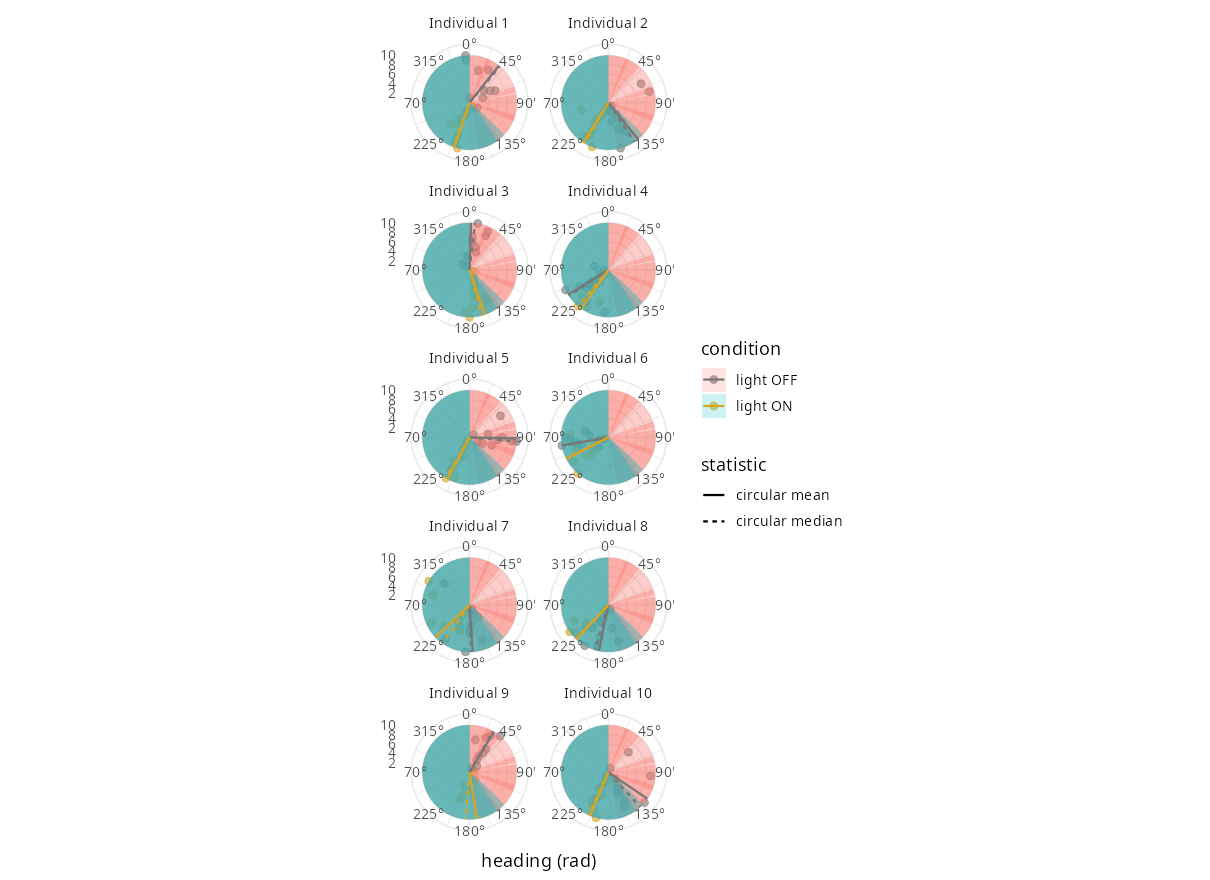

In [5]:
# Polar per-individual raw headings, circular mean (solid) and median
# (dashed), with the floodlight at -135 degrees.
# Polar raw-data grid following the Python twin (beetles_plots.py,
# plot_data_polar): each heading sits at (heading, trial number), so the
# radial axis is the trial order 1-10; each condition is summarised by a
# solid circular-mean spoke, a dashed circular-median spoke and a
# transparent wedge of mean +/- one normalized circular standard
# deviation. 0 degrees is at the top and the angle axis runs clockwise
# with a label every 45 degrees.
raw_plot <- transform(data, theta = HeadingRadians %% (2 * pi), radius = Trial)
radial_max <- 10
circ_sd_norm <- function(a) {
  as.numeric(circular::sd.circular(vmu(a), high = pi, low = -pi,
    normalize = TRUE))[1]
}
blocks <- do.call(rbind, lapply(split(data, list(data$Individual,
  data$condition), drop = TRUE), function(g) {
  a <- c(circ_mean(g$HeadingRadians),
    as.numeric(circular::median.circular(vmu(g$HeadingRadians)))[1])
  data.frame(Individual = g$Individual[1], condition = g$condition[1],
    theta = a %% (2 * pi), radius = 0, radius_end = radial_max,
    wedge_center = a[1], wedge_sd = circ_sd_norm(g$HeadingRadians),
    statistic = c("circular mean", "circular median"))
}))
# Wedge sector mean +/- sd, split into at most two polygons across the
# (0, 2 pi) seam; each polygon is origin, outer arc, origin.
wedges <- do.call(rbind, lapply(seq_len(nrow(blocks)), function(k) {
  lo <- mod_circular(blocks$wedge_center[k] - blocks$wedge_sd[k])
  hi <- mod_circular(blocks$wedge_center[k] + blocks$wedge_sd[k])
  chunks <- if (lo < hi) {
    list(seq(lo, hi, length.out = 100L))
  } else {
    list(seq(lo, 2 * pi, length.out = 50L), c(0, seq(0, hi, length.out = 49L)))
  }
  do.call(rbind, lapply(seq_along(chunks), function(j) {
    th <- chunks[[j]]
    data.frame(theta = c(th[1L], th[-1L], th[length(th)]),
      radius = c(0, rep(radial_max, length(th) - 1L), 0),
      condition = blocks$condition[k], group = 10L * k + j)
  }))
}))
p_data <- ggplot(raw_plot, aes(theta, radius, colour = condition)) +
  geom_point(alpha = 0.6, size = 2) +
  geom_polygon(data = wedges, aes(theta, radius, group = group,
    fill = condition), inherit.aes = FALSE, alpha = 0.2, colour = NA) +
  geom_segment(data = blocks,
    aes(x = theta, xend = theta, y = radius, yend = radius_end,
        colour = condition, linetype = statistic),
    inherit.aes = FALSE, linewidth = 0.7) +
  scale_x_continuous(limits = c(0, 2 * pi),
    breaks = (0:7) * pi / 4,
    labels = c("0°", "45°", "90°", "135°",
      "180°", "225°", "270°", "315°"),
    expand = c(0, 0)) +
  scale_y_continuous(limits = c(0, radial_max + 1),
    breaks = seq(2, radial_max, by = 2)) +
  coord_polar() +
  facet_wrap(~ Individual, ncol = 2,
    labeller = as_labeller(setNames(
      paste0("Individual ", seq_len(nlevels(data$Individual))),
      levels(data$Individual)))) +
  scale_colour_manual(values = condition_colors) +
  labs(x = "heading (rad)", y = "") + theme(legend.position = "right")
save_figure(p_data, "data_individual_polar_grid", 11, 8)


## 2. Specify the treatment model

Both submodels have a population intercept and `Light` effect plus an
independent intercept and `Light` deviation per `Individual`:
`HeadingRadians ~ Light + (1 + Light | Individual)` and
`kappa ~ Light + (1 + Light | Individual)`.

Mean-direction priors are von Mises: intercept `(0, 1e-6)`, treatment
`(0, 2)`; each individual-effect vector has concentration with
`LogNormal(log(30), 0.5)` hyperprior. Concentration coefficients are on
the pre-softplus scale: intercept `Normal(inverse_softplus(5), 1)`,
treatment `Normal(0, 1)`, independent Normal individual deviations
with `HalfNormal(1)` scales. Explicit `0 + Intercept` prevents predictor
centering in the concentration formula, as in Python.


In [6]:
# Preserve independent circular intercept and slope deviations. brms's
# ordinary (1 + Light | Individual) mu term would impose Gaussian effects.
# Following the Rmd, represent them as nonlinear coefficient vectors.
form_vonmises <- bf(HeadingRadians ~ mu,
  nlf(mu ~ beta0 + bias0 + Light * bias1),
  beta0 ~ 1 + Light,
  bias0 ~ 0 + Individual,
  bias1 ~ 0 + Individual,
  kappa ~ 0 + Intercept + Light + (1 + Light || Individual),
  family = unwrap_von_mises)

# One LogNormal(log(30), 0.5) hyperprior for each direction-effect vector,
# as in Python. Direct positive parameters need no softplus Jacobian.
stan_direction_priors <- stanvar(scode = "
  real<lower=0> kmu_intercept;
  real<lower=0> kmu_slope;
", block = "parameters") + stanvar(scode = "
  real unwrap_von_mises_vect_lpdf(vector y, real mu, real kappa) {
    real lp = 0;
    for (i in 1:num_elements(y)) {
      lp += unwrap_von_mises_lpdf(y[i] | mu, kappa);
    }
    return lp;
  }
", block = "functions")
prior_vonmises <- (
  # Bounds identify one period and match PyMC's VonMises support.
  # brms injects the lb/ub source text VERBATIM into the Stan declaration
  # (no evaluation) and Stan has no 'pi' bound constant - use literals.
  # Uniform factors add constants only. Apply the von Mises log densities
  # explicitly so brms does not request nonexistent custom-prior CDFs
  # when normalizing a bounded coefficient prior.
  prior("uniform(-pi(), pi())", class = "b", nlpar = "beta0", lb = -3.141592653589793, ub = 3.141592653589793) +
  prior("uniform(-pi(), pi())", class = "b", nlpar = "bias0", lb = -3.141592653589793, ub = 3.141592653589793) +
  prior("uniform(-pi(), pi())", class = "b", nlpar = "bias1", lb = -3.141592653589793, ub = 3.141592653589793) +
  set_prior("target += unwrap_von_mises_lpdf(b_beta0[1] | 0, 1e-6)", check = FALSE) +
  set_prior("target += unwrap_von_mises_lpdf(b_beta0[2] | 0, 2)", check = FALSE) +
  set_prior("target += unwrap_von_mises_vect_lpdf(b_bias0 | 0, kmu_intercept)",
            check = FALSE) +
  set_prior("target += unwrap_von_mises_vect_lpdf(b_bias1 | 0, kmu_slope)",
            check = FALSE) +
  set_prior("target += lognormal_lpdf(kmu_intercept | log(30), 0.5)",
            check = FALSE) +
  set_prior("target += lognormal_lpdf(kmu_slope | log(30), 0.5)",
            check = FALSE) +
  prior("normal(log(exp(5) - 1), 1)", class = "b", dpar = "kappa",
        coef = "Intercept") +
  prior("normal(0, 1)", class = "b", dpar = "kappa",
        coef = "Light") +
  prior("normal(0, 1)", class = "sd", dpar = "kappa")
)
# EQUIVALENCE NOTE: || removes brms's default intercept/slope correlation;
# the Python priors are separate independent effects, with no LKJ term.
# Gaussian kappa effects use brms's non-centered parameterization and
# positive sd bounds turn normal(0, 1) into HalfNormal(1).
# The nonlinear mu vectors retain centered von Mises effects, not normal
# random effects. Verify their generated names/bounds/priors when baking.
prior_vonmises


prior,class,coef,group,resp,dpar,nlpar,lb,ub,tag,source
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
"uniform(-pi(), pi())",b,,,,,beta0,-3.14159265358979,3.14159265358979,,user
"uniform(-pi(), pi())",b,,,,,bias0,-3.14159265358979,3.14159265358979,,user
"uniform(-pi(), pi())",b,,,,,bias1,-3.14159265358979,3.14159265358979,,user
"target += unwrap_von_mises_lpdf(b_beta0[1] | 0, 1e-6)",,,,,,,,,,user
"target += unwrap_von_mises_lpdf(b_beta0[2] | 0, 2)",,,,,,,,,,user
"target += unwrap_von_mises_vect_lpdf(b_bias0 | 0, kmu_intercept)",,,,,,,,,,user
"target += unwrap_von_mises_vect_lpdf(b_bias1 | 0, kmu_slope)",,,,,,,,,,user
"target += lognormal_lpdf(kmu_intercept | log(30), 0.5)",,,,,,,,,,user
"target += lognormal_lpdf(kmu_slope | log(30), 0.5)",,,,,,,,,,user


## 3. Fit

Full sampling uses four chains with 2,000 warmup and 2,000 retained
draws per chain. Quick mode (`UNWRAP_R_QUICK=1`) uses four chains with
1,500 warmup and 1,500 retained draws; `adapt_delta = 0.97` allows more
conservative adaptation of the grouped model.

The bounded angular coefficients also carry a wrap-equivalence: the
likelihood pins each trial's wrapped sum of direction effects, so
different splits of the intercept and deviation vectors can encode the
same wrapped directions, and these equivalent regions are separated by
high posterior barriers. Chains seeded into different regions each
converge internally but read as non-mixed under R-hat. The sampler is
therefore initialized, per chain and from the per-group circular means
of the data, in one common region (the `init` list in the fit call
below): this changes only the sampler's path, never the posterior.


In [7]:
# Inspect the generated Stan before sampling: each direction coefficient
# must have [-pi, pi] bounds; kappa has independent non-centered effects.
stan_code <- make_stancode(form_vonmises, data = data,
  prior = prior_vonmises,
  stanvars = stan_unwrap_fun + modulo_circular_fun + stan_direction_priors)
stopifnot(grepl("kmu_intercept", stan_code, fixed = TRUE),
          grepl("unwrap_von_mises_vect_lpdf", stan_code, fixed = TRUE))

# NUTS on the bounded angular coefficients: their (-pi, pi] components
# carry 2*pi-equivalent posterior classes (the per-individual heading
# sums straddle the angular seam), separated by high posterior barriers.
# Chains exploring different classes fail sine R-hat/ESS even though
# every chain is individually converged; cmdstanr's common default init
# (and wide anchor jitter) puts different chains in different classes.
# Seed all chains in one class from the data: intercept anchor = base-
# condition circular mean, slope anchor = circular mean difference,
# per-individual deviation anchors = condition-mean differences, jitter
# too small to cross any seam. Initialization changes only the sampler
# path, never the posterior.
g_off_ind <- as.numeric(tapply(data$HeadingRadians[data$Light == 0],
  data$Individual[data$Light == 0], circ_mean))
g_on_ind <- as.numeric(tapply(data$HeadingRadians[data$Light == 1],
  data$Individual[data$Light == 1], circ_mean))
mu_anchor <- as.numeric(circ_mean(data$HeadingRadians[data$Light == 0]))
ls_anchor <- as.numeric(mod_circular(
  circ_mean(data$HeadingRadians[data$Light == 1]) -
  circ_mean(data$HeadingRadians[data$Light == 0])))
stopifnot(length(g_off_ind) == length(levels(data$Individual)),
  length(g_on_ind) == length(levels(data$Individual)),
  abs(mu_anchor) < pi - 0.2, abs(ls_anchor) < pi - 0.5)
mk_init <- function(anchor_seed) {
  set.seed(anchor_seed)
  j <- function(n) runif(n, -0.08, 0.08)
  list(b_beta0 = as.numeric(c(mu_anchor + j(1), ls_anchor + j(1))),
    b_bias0 = as.numeric(mod_circular(g_off_ind - mu_anchor) + j(length(g_off_ind))),
    b_bias1 = as.numeric(mod_circular(g_on_ind - mu_anchor - ls_anchor) + j(length(g_on_ind))),
    kmu_intercept = 30, kmu_slope = 30)
}
fit <- unwrap_load_fit_cache("beetles_fit", SEED, ITER, WARMUP)
if (is.null(fit)) {
  fit <- brm(form_vonmises, data = data,
    stanvars = stan_unwrap_fun + modulo_circular_fun + stan_direction_priors,
    prior = prior_vonmises, backend = "cmdstanr",
    chains = CHAINS, iter = ITER, warmup = WARMUP, cores = CHAINS,
    seed = SEED,
    init = lapply(seq_len(CHAINS), function(k) mk_init(SEED + k)),
    control = list(adapt_delta = ADAPT_DELTA))
  unwrap_save_fit_cache("beetles_fit", fit, SEED, ITER, WARMUP)
}


Loading required namespace: rstan



Unwrap fit cache: 'beetles_fit' is stale; refitting.



Start sampling



Init values were only set for a subset of parameters. 
Missing init values for the following parameters:
 - chain 1: b_kappa, sd_1, z_1
 - chain 2: b_kappa, sd_1, z_1
 - chain 3: b_kappa, sd_1, z_1
 - chain 4: b_kappa, sd_1, z_1

To disable this message use options(cmdstanr_warn_inits = FALSE).




Running MCMC with 4 parallel chains...

Chain 1 Iteration:    1 / 4000 [  0%]  (Warmup) 
Chain 2 Iteration:    1 / 4000 [  0%]  (Warmup) 
Chain 3 Iteration:    1 / 4000 [  0%]  (Warmup) 
Chain 4 Iteration:    1 / 4000 [  0%]  (Warmup) 
Chain 3 Iteration:  100 / 4000 [  2%]  (Warmup) 
Chain 2 Iteration:  100 / 4000 [  2%]  (Warmup) 
Chain 1 Iteration:  100 / 4000 [  2%]  (Warmup) 
Chain 4 Iteration:  100 / 4000 [  2%]  (Warmup) 
Chain 4 Iteration:  200 / 4000 [  5%]  (Warmup) 
Chain 2 Iteration:  200 / 4000 [  5%]  (Warmup) 
Chain 1 Iteration:  200 / 4000 [  5%]  (Warmup) 
Chain 2 Iteration:  300 / 4000 [  7%]  (Warmup) 
Chain 4 Iteration:  300 / 4000 [  7%]  (Warmup) 
Chain 3 Iteration:  200 / 4000 [  5%]  (Warmup) 
Chain 1 Iteration:  300 / 4000 [  7%]  (Warmup) 
Chain 2 Iteration:  400 / 4000 [ 10%]  (Warmup) 
Chain 4 Iteration:  400 / 4000 [ 10%]  (Warmup) 
Chain 1 Iteration:  400 / 4000 [ 10%]  (Warmup) 
Chain 3 Iteration:  300 / 4000 [  7%]  (Warmup) 
Chain 2 Iteration:  500 / 400

## Diagnostics and traces

Report the divergence count first: if the per-iteration flags were not
retained, the output says so, and that does not establish zero
divergences. Circular direction coefficients use `Rhat_unwrap`; all
diagnostics preserve the iteration-by-chain structure. Review the
summary table and any flagged parameters, including individual effects
and hyperparameters, before interpreting the posterior.


In [8]:
diagnose_fit <- function(fit, circular_parameters = character()) {
  # NUTS divergences. Not every brms/cmdstanr combination keeps the
  # per-iteration divergence flag in the fit object, so probe for it and
  # report what the fit object actually carries (the R-hat and ESS values
  # below are the primary convergence checks either way).
  divergences <- tryCatch({
    div_flags <- lapply(fit$fit@sim$samples, function(ch) ch[["divergent"]])
    if (any(vapply(div_flags, is.null, logical(1)))) NA_real_
    else sum(unlist(div_flags))
  }, error = function(e) NA_real_)
  if (is.na(divergences)) {
      cat("Divergences: not retained in this fit object (see R-hat/ESS below).\n")
  } else {
      cat("Divergences:", divergences, "\n")
  }
  available <- posterior::variables(posterior::as_draws_array(fit))
  parameters <- available[grepl("^(b_|sd_|r_|kmu_)", available)]
  draws_array <- posterior::subset_draws(posterior::as_draws_array(fit),
                                         variable = parameters)
  out <- do.call(rbind, lapply(parameters, function(p) {
    # Preserve iteration x chain shape: flattening loses between-chain
    # information and would make the R-hat/ESS checks misleading.
    x <- as.matrix(draws_array[, , p])
    angular <- p %in% circular_parameters
    z <- if (angular) mod_circular(x - circ_mean(x)) else x
    stopifnot(all(is.finite(x)))
    data.frame(parameter = p,
      mean = if (angular) circ_mean(x) else mean(x),
      sd = if (angular) circ_sd(x) else sd(as.numeric(x)),
      rhat = if (angular) Rhat_unwrap(x, method = "sine") else posterior::rhat(x),
      ess_bulk = posterior::ess_bulk(z),
      row.names = NULL, check.names = FALSE)
  }))
  out$rhat <- round(out$rhat, 4)
  out$ess_bulk <- round(out$ess_bulk, 1)
  out
}

available <- posterior::variables(posterior::as_draws_array(fit))
circular_parameters <- available[grepl("^b_(beta0|bias0|bias1)_", available)]
summary_frame <- diagnose_fit(fit, circular_parameters)
summary_frame


Divergences: not retained in this fit object (see R-hat/ESS below).


parameter,mean,sd,rhat,ess_bulk
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
b_beta0_Intercept,2.249542599,0.3836867,1.0006,773.9
b_beta0_Light,1.258525418,0.2561273,1.0004,1242.8
b_bias0_Individual1,-1.403758985,0.4247630,1.0008,889.6
b_bias0_Individual2,0.197549406,0.3966900,1.0003,887.8
b_bias0_Individual3,-2.108442788,0.4219974,1.0006,866.9
b_bias0_Individual4,1.805344826,0.4159440,1.0002,894.6
b_bias0_Individual5,-0.596491791,0.3942498,1.0003,849.3
b_bias0_Individual6,2.199839022,0.4131243,1.0004,884.6
b_bias0_Individual7,0.733594849,0.4103397,1.0009,948.5


In [9]:
summary_frame[!is.finite(summary_frame$rhat) | summary_frame$rhat >= 1.01 |
              !is.finite(summary_frame$ess_bulk) | summary_frame$ess_bulk <= 400, ]


parameter,mean,sd,rhat,ess_bulk
<chr>,<dbl>,<dbl>,<dbl>,<dbl>


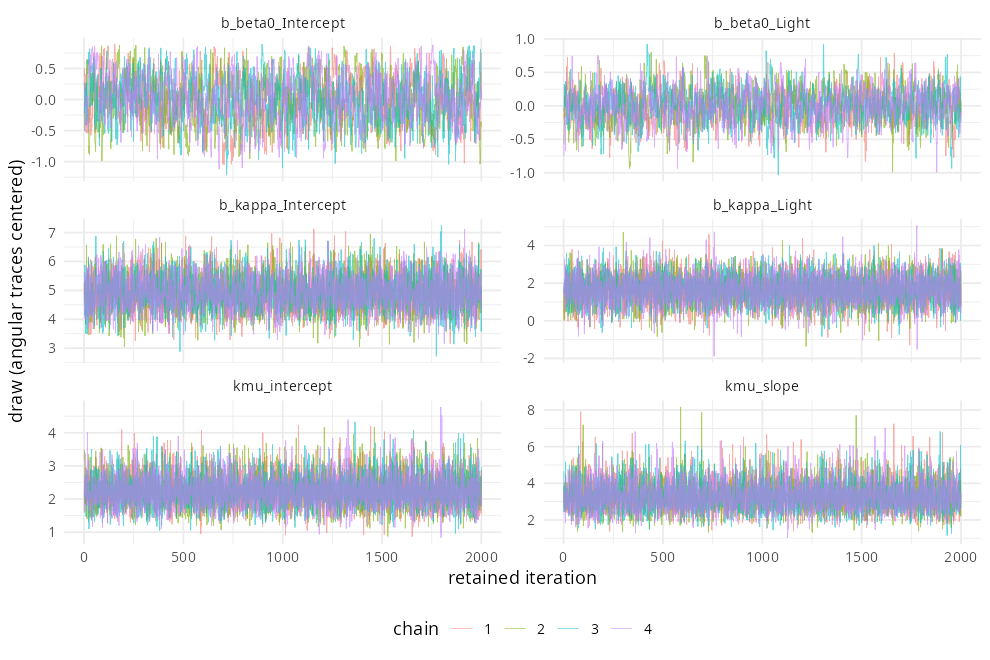

In [10]:
trace_parameters <- c("b_beta0_Intercept", "b_beta0_Light",
  "b_kappa_Intercept", "b_kappa_Light", "kmu_intercept", "kmu_slope")

# as_draws_df is wide: explicitly assemble a long trace table.
draws_df <- posterior::as_draws_df(posterior::subset_draws(
    posterior::as_draws_array(fit), variable = trace_parameters))
trace_df <- do.call(rbind, lapply(trace_parameters, function(p) {
  value <- as.numeric(draws_df[[p]])
  if (p %in% circular_parameters) value <- mod_circular(value - circ_mean(value))
  data.frame(parameter = p, value = value,
             iteration = draws_df[[".iteration"]],
             chain = factor(draws_df[[".chain"]]))
}))
p_trace <- ggplot(trace_df, aes(iteration, value, colour = chain)) +
  geom_line(alpha = 0.6, linewidth = 0.25) +
  facet_wrap(~ parameter, scales = "free_y", ncol = 2) +
  labs(x = "retained iteration", y = "draw (angular traces centered)") +
  theme(legend.position = "bottom")
save_figure(p_trace, "trace", 9, 6)


## 4. Directions, within-individual concentration, and alignment

Combine fixed and individual effects for both conditions. Direction
intervals are circular; concentration enters through softplus.
$R(\kappa)=I_1(\kappa)/I_0(\kappa)$ describes within-individual precision;
the resultant length of the individual mean directions describes
between-individual alignment. These are separate quantities.


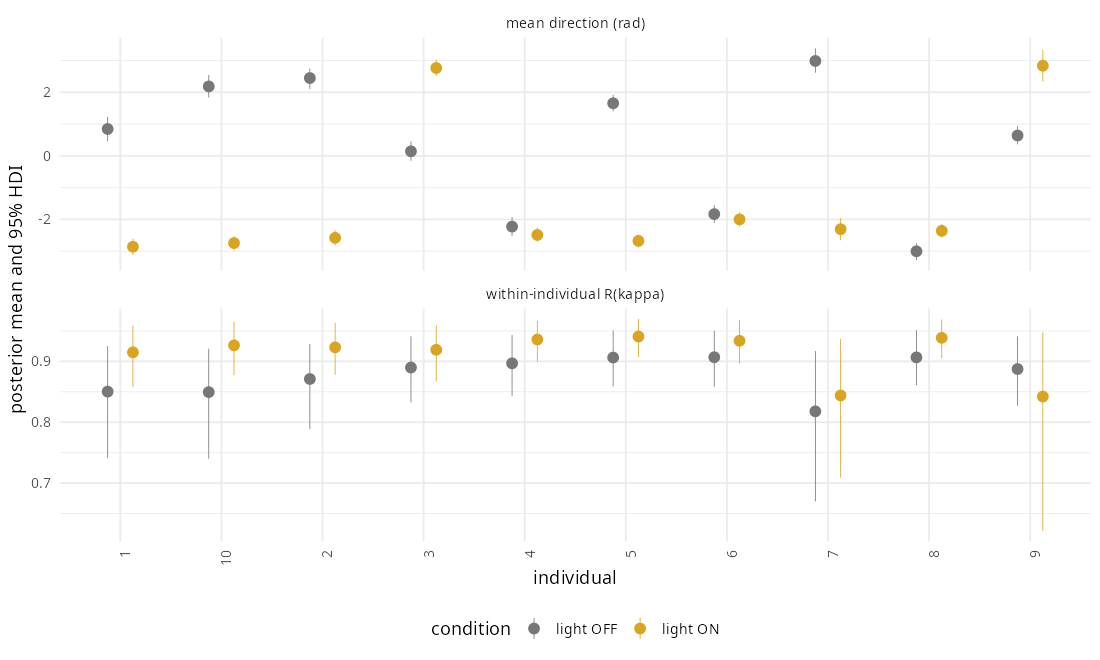

In [11]:
ids <- levels(data$Individual)
prediction_data <- expand.grid(Individual = ids, Light = c(0, 1),
                               KEEP.OUT.ATTRS = FALSE, stringsAsFactors = FALSE)
prediction_data$Individual <- factor(prediction_data$Individual, levels = ids)
prediction_data$condition <- factor(prediction_data$Light,
                                     levels = c(0, 1), labels = condition_labels)
# Draw x individual-condition matrices. Evaluate each fitted distributional
# predictor explicitly; no arithmetic averaging across the angular seam.
mu <- mod_circular(posterior_linpred(fit, newdata = prediction_data,
                                     transform = FALSE, dpar = "mu"))
kappa <- posterior_linpred(fit, newdata = prediction_data,
                           transform = TRUE, dpar = "kappa")
stopifnot(identical(dim(mu), dim(kappa)), all(kappa > 0))
J <- length(ids)
pre <- seq_len(J)
post <- J + pre
group_alignment <- cbind(
  Mod(rowMeans(exp(1i * mu[, pre, drop = FALSE]))),
  Mod(rowMeans(exp(1i * mu[, post, drop = FALSE]))))
individual_summary <- do.call(rbind, lapply(seq_len(nrow(prediction_data)), function(j) {
  rbind(data.frame(id = as.character(prediction_data$Individual[j]),
    condition = prediction_data$condition[j], quantity = "mean direction (rad)",
    as.list(interval_row(mu[, j], angular = TRUE))),
    data.frame(id = as.character(prediction_data$Individual[j]),
    condition = prediction_data$condition[j], quantity = "within-individual R(kappa)",
    as.list(interval_row(A1_safe(kappa[, j])))))
}))
p_individual <- ggplot(individual_summary,
  aes(id, mean, colour = condition, group = condition)) +
  geom_pointrange(aes(ymin = low, ymax = high),
    position = position_dodge(width = 0.5), linewidth = 0.25) +
  facet_wrap(~ quantity, scales = "free_y", ncol = 1) +
  scale_colour_manual(values = condition_colors) +
  labs(x = "individual", y = "posterior mean and 95% HDI") +
  theme(axis.text.x = element_text(angle = 90, hjust = 1),
        legend.position = "bottom")
save_figure(p_individual, "individual_posteriors", 10, 6)


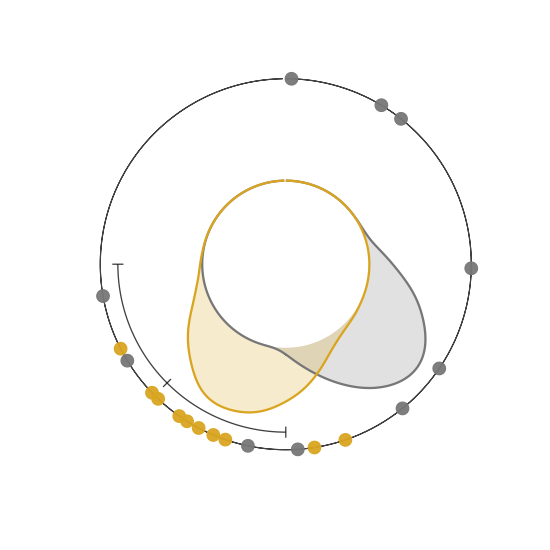

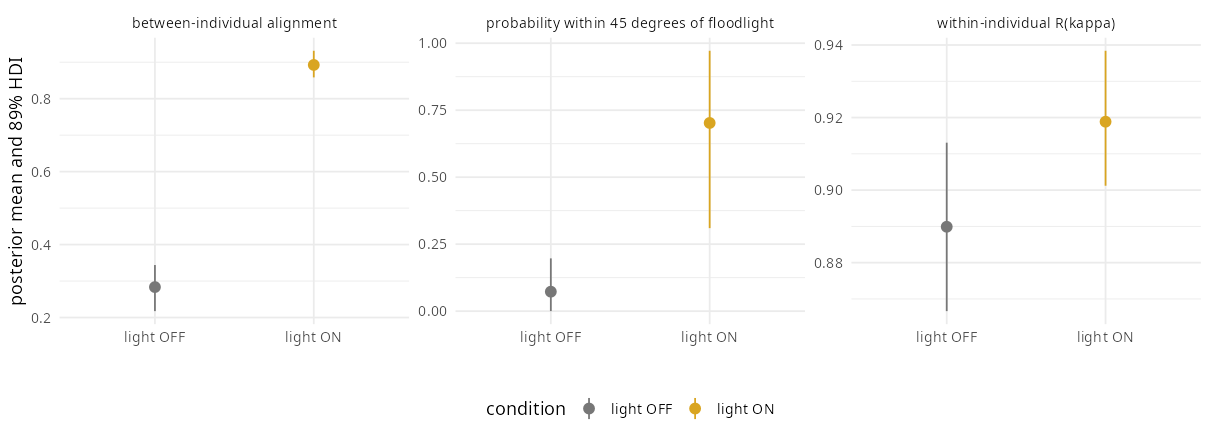

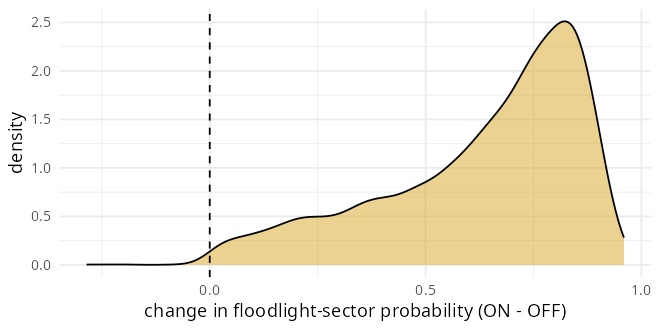

In [12]:
fixed <- as.data.frame(posterior::as_draws_df(fit))
population_mu <- cbind(mod_circular(fixed$b_beta0_Intercept),
  mod_circular(fixed$b_beta0_Intercept + fixed$b_beta0_Light))
theta <- seq(-pi, pi, length.out = 361)
mu_kde <- do.call(rbind, lapply(1:2, function(c) {
  data.frame(theta = theta %% (2 * pi),
    density = vapply(theta, function(t) mean(exp(vm_logpdf(t, population_mu[, c], 80))), numeric(1)),
    condition = condition_labels[c])
}))
# Polar population-mu KDE following the Python twin (beetles_plots.py,
# plot_polar_mu_kde): the radius is 0.5 + 0.5 * kde/max_kde, so the
# density-zero ring sits at radius 0.5 and the shared peak at 1.0. The
# outer reference ring at radius 1.11 carries each beetle's per-condition
# circular mean; the floodlight sector at -135 +/- 45 degrees is a black
# arc with end-and-centre ticks. The twin carries no tick labels here.
max_kde_mu <- max(mu_kde$density)
ring_base <- 0.5
mu_kde$base <- ring_base
mu_kde$r <- ring_base + 0.5 * mu_kde$density / max_kde_mu
r_pts <- ring_base + 0.5 * 1.22
# The marked arc is the +/-45-degree floodlight sector, centered at -135.
flood_dir <- -3 * pi / 4
r_on_max <- max(mu_kde$r[mu_kde$condition == condition_labels[2]])
r_mark <- r_on_max + 0.4 * (r_pts - r_on_max)
cap <- 0.03 * r_pts
flood_arc <- data.frame(theta = seq(flood_dir - pi / 4, flood_dir + pi / 4,
  length.out = 100L) %% (2 * pi), r = r_mark)
flood_ticks <- data.frame(theta = c(flood_dir - pi / 4, flood_dir,
  flood_dir + pi / 4) %% (2 * pi), lo = r_mark - cap, hi = r_mark + cap)
ind_means <- do.call(rbind, lapply(split(data, list(data$Individual,
  data$condition), drop = TRUE), function(g) data.frame(
    theta = circ_mean(g$HeadingRadians) %% (2 * pi),
    condition = g$condition[1])))
ind_means$r <- r_pts
p_mu <- ggplot(mu_kde, aes(theta, r, colour = condition)) +
  geom_ribbon(aes(ymin = base, ymax = r, fill = condition),
    alpha = 0.22, colour = NA) +
  geom_line(linewidth = 0.7) +
  geom_path(data = data.frame(theta = theta %% (2 * pi), r = r_pts),
    inherit.aes = FALSE, aes(theta, r), colour = "grey25", linewidth = 0.35) +
  geom_line(data = flood_arc, inherit.aes = FALSE, aes(theta, r),
    colour = "black", linewidth = 0.4, alpha = 0.75) +
  geom_segment(data = flood_ticks, inherit.aes = FALSE,
    aes(x = theta, xend = theta, y = lo, yend = hi),
    colour = "black", linewidth = 0.4, alpha = 0.75) +
  geom_point(data = ind_means, inherit.aes = FALSE,
    aes(theta, r, colour = condition), size = 3.5, alpha = 0.95) +
  scale_x_continuous(limits = c(0, 2 * pi), expand = c(0, 0)) +
  scale_y_continuous(limits = c(0, r_pts * 1.1), expand = c(0, 0)) +
  coord_polar() +
  scale_colour_manual(values = condition_colors) +
  scale_fill_manual(values = condition_colors) +
  labs(x = "", y = "") +
  theme(legend.position = "none", axis.text = element_blank(),
    axis.ticks = element_blank(), panel.grid = element_blank(),
    panel.border = element_blank())
save_figure(p_mu, "treat_polar_mu_kde_clean", 5, 5)

# Python's main treatment figure uses the fixed-effect (zero individual
# deviation) concentration and predictive density, not an average over
# the observed individuals or a marginal prediction for a new individual.
population_kappa <- cbind(softplus(fixed$b_kappa_Intercept),
  softplus(fixed$b_kappa_Intercept + fixed$b_kappa_Light))
FLOOD_DIR <- -135 * pi / 180
arc <- seq(FLOOD_DIR - pi / 4, FLOOD_DIR + pi / 4, length.out = 181)
delta <- diff(arc)[1]
flood_mass <- matrix(0, nrow = nrow(population_mu), ncol = 2)
for (j in 1:2) {
  weights <- c(0.5, rep(1, length(arc) - 2), 0.5)
  for (a in seq_along(arc)) {
    flood_mass[, j] <- flood_mass[, j] + weights[a] * delta *
      exp(vm_logpdf(arc[a], population_mu[, j], population_kappa[, j]))
  }
}
within_R <- A1_safe(population_kappa)
mass <- flood_mass
treatment_statistics <- list("within-individual R(kappa)" = within_R,
  "between-individual alignment" = group_alignment,
  "probability within 45 degrees of floodlight" = mass)
stat_df <- do.call(rbind, lapply(names(treatment_statistics), function(q) {
  do.call(rbind, lapply(1:2, function(c) data.frame(quantity = q,
    condition = condition_labels[c],
    as.list(interval_row(treatment_statistics[[q]][, c], prob = 0.89)))))
}))
p_concentration <- ggplot(stat_df, aes(condition, mean, colour = condition)) +
  geom_pointrange(aes(ymin = low, ymax = high)) +
  facet_wrap(~ quantity, scales = "free_y") +
  scale_colour_manual(values = condition_colors) +
  labs(x = "", y = "posterior mean and 89% HDI") + theme(legend.position = "bottom")
save_figure(p_concentration, "treat_concentration_plus_floodlight", 11, 4)
mass_delta <- data.frame(delta = mass[, 2] - mass[, 1])
p_mass_delta <- ggplot(mass_delta, aes(delta)) + geom_density(fill = "#D9A521", alpha = 0.5) +
  geom_vline(xintercept = 0, linetype = "dashed") +
  labs(x = "change in floodlight-sector probability (ON - OFF)", y = "density")
save_figure(p_mass_delta, "floodlight_mass_change", 6, 3)


## 5. Change in between-individual concentration

Fit a von Mises concentration to the distribution of individuals' mean
directions, first using posterior point estimates and then within every
posterior draw. This matches the Python post-hoc $\kappa_\mu$ estimand.
Inverting the Bessel ratio gives the same concentration MLE as fitting
a unit-scale von Mises density. Report the change as ON minus OFF;
do not confuse it with within-individual $\kappa$ or the prior
concentration of individual intercept/slope deviations.


In [13]:
individual_point <- apply(mu, 2, circ_mean)
kappamu_point <- c(OFF = inverse_A1(resultant(individual_point[pre])),
                    ON = inverse_A1(resultant(individual_point[post])))
kappamu_point


OFF        ON 
0.5961232 5.3269500

In [14]:
kappamu <- apply(group_alignment, 2, function(r) vapply(r, inverse_A1, numeric(1)))
kappamu <- cbind(kappa_mu_OFF = kappamu[, 1], kappa_mu_ON = kappamu[, 2],
                  kappa_mu_delta = kappamu[, 2] - kappamu[, 1])
stopifnot(all(is.finite(kappamu)))
kappamu_summary <- do.call(rbind, lapply(colnames(kappamu), function(p) {
  data.frame(parameter = p, as.list(interval_row(kappamu[, p])))
}))
kappamu_summary


parameter,mean,low,high
<chr>,<dbl>,<dbl>,<dbl>
kappa_mu_OFF,0.5931639,0.4155642,0.7667878
kappa_mu_ON,5.1925745,3.3104615,7.3373022
kappa_mu_delta,4.5994106,2.6308509,6.6955194


In [15]:
mean(kappamu[, "kappa_mu_delta"] > 0)


[1] 1

## Posterior predictive checks

The first predictive check compares hierarchical bootstraps of the
observations with posterior response-parameter summaries: group mean
direction, between-individual alignment, and each individual's direction
and within-individual concentration. Resample individuals first, then
trials/windows within each condition. Open markers show data bootstraps;
filled markers show the posterior, with 95% HDIs. The group mean panel
uses the fixed direction effects.


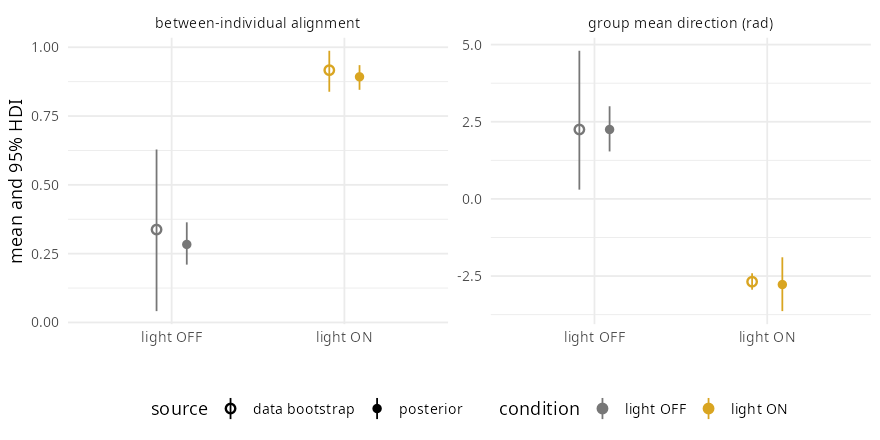

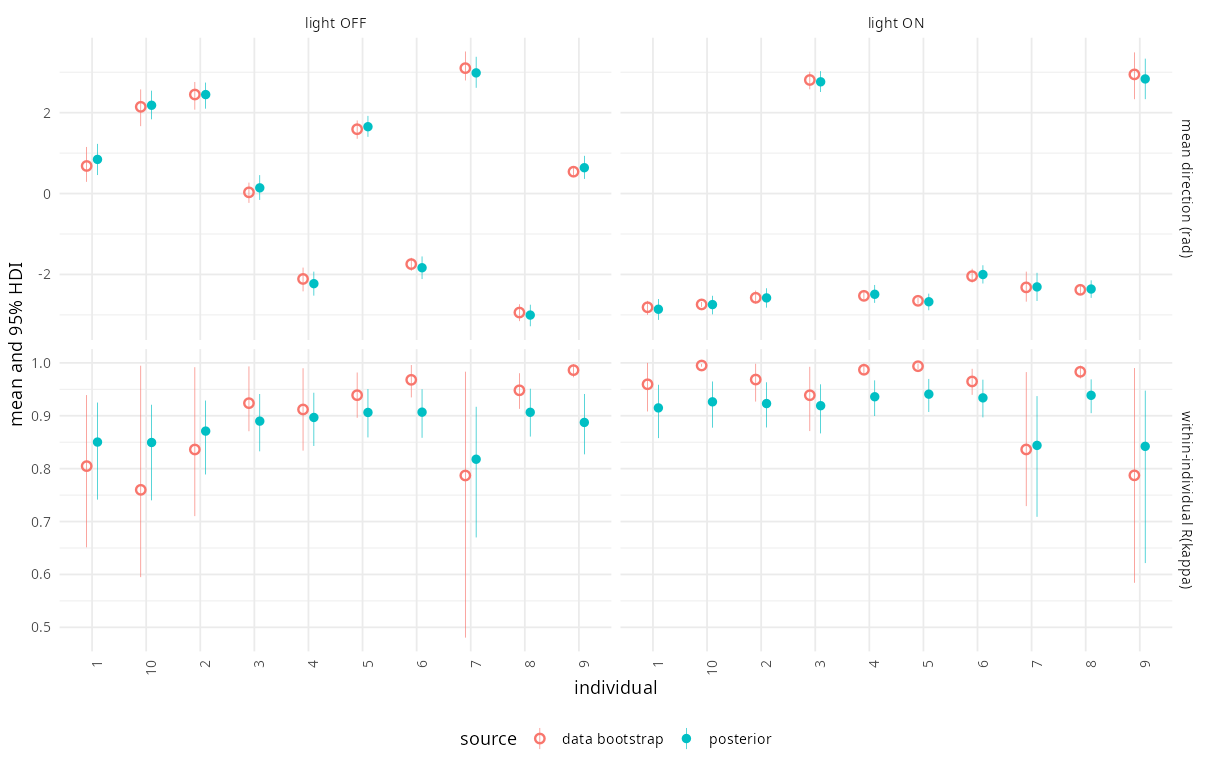

In [16]:
# Python's supplemental PPC compares data bootstraps with fitted response
# parameters (not with a new stochastic dataset). Reproduce that check,
# then add a conventional replicated-data check below.
B_GROUP <- if (quick_run) 200L else 2000L
B_INDIV <- if (quick_run) 150L else 1500L
ys <- lapply(seq_len(nrow(prediction_data)), function(j) {
  data$HeadingRadians[as.character(data$Individual) ==
    as.character(prediction_data$Individual[j]) &
    data$Light == prediction_data$Light[j]]
})
stopifnot(all(lengths(ys) > 0L))
bootstrap_pair <- function(y, B) {
  z <- replicate(B, mean(exp(1i * y[sample.int(length(y), length(y), replace = TRUE)])))
  list(mu = Arg(z), R = Mod(z))
}
set.seed(SEED + 10L)
boot_individual <- lapply(ys, bootstrap_pair, B = B_INDIV)
boot_group_mu <- boot_group_R <- matrix(0, nrow = B_GROUP, ncol = 2)
for (b in seq_len(B_GROUP)) {
  selected <- sample.int(J, J, replace = TRUE)
  for (c in 1:2) {
    jj <- selected + (c - 1L) * J
    directions <- vapply(jj, function(j) {
      y <- ys[[j]]
      circ_mean(y[sample.int(length(y), length(y), replace = TRUE)])
    }, numeric(1))
    boot_group_mu[b, c] <- circ_mean(directions)
    boot_group_R[b, c] <- resultant(directions)
  }
}
fixed <- as.data.frame(posterior::as_draws_df(fit))
population_mu <- cbind(mod_circular(fixed$b_beta0_Intercept),
  mod_circular(fixed$b_beta0_Intercept + fixed$b_beta0_Light))
ppc_group <- do.call(rbind, lapply(1:2, function(c) {
  rbind(
    data.frame(condition = condition_labels[c], source = "data bootstrap",
      quantity = "group mean direction (rad)",
      as.list(interval_row(boot_group_mu[, c], TRUE))),
    data.frame(condition = condition_labels[c], source = "posterior",
      quantity = "group mean direction (rad)",
      as.list(interval_row(population_mu[, c], TRUE))),
    data.frame(condition = condition_labels[c], source = "data bootstrap",
      quantity = "between-individual alignment",
      as.list(interval_row(boot_group_R[, c]))),
    data.frame(condition = condition_labels[c], source = "posterior",
      quantity = "between-individual alignment",
      as.list(interval_row(group_alignment[, c]))))
}))
p_group_ppc <- ggplot(ppc_group,
  aes(condition, mean, colour = condition, shape = source)) +
  geom_pointrange(aes(ymin = low, ymax = high),
    position = position_dodge(width = 0.35)) +
  facet_wrap(~ quantity, scales = "free_y") +
  scale_colour_manual(values = condition_colors) +
  scale_shape_manual(values = c("data bootstrap" = 1, "posterior" = 16)) +
  labs(x = "", y = "mean and 95% HDI") + theme(legend.position = "bottom")
save_figure(p_group_ppc, "ppc_group", 8, 4)

ppc_individual <- do.call(rbind, lapply(seq_along(ys), function(j) {
  rbind(data.frame(id = as.character(prediction_data$Individual[j]),
    condition = prediction_data$condition[j], source = "data bootstrap",
    quantity = "mean direction (rad)",
    as.list(interval_row(boot_individual[[j]]$mu, TRUE))),
    data.frame(id = as.character(prediction_data$Individual[j]),
    condition = prediction_data$condition[j], source = "data bootstrap",
    quantity = "within-individual R(kappa)",
    as.list(interval_row(boot_individual[[j]]$R))),
    transform(individual_summary[individual_summary$id ==
      as.character(prediction_data$Individual[j]) &
      individual_summary$condition == prediction_data$condition[j], ],
      source = "posterior"))
}))
p_ind_ppc <- ggplot(ppc_individual,
  aes(id, mean, colour = source, shape = source)) +
  geom_pointrange(aes(ymin = low, ymax = high),
    position = position_dodge(width = 0.4), linewidth = 0.2) +
  facet_grid(quantity ~ condition, scales = "free_y") +
  scale_shape_manual(values = c("data bootstrap" = 1, "posterior" = 16)) +
  labs(x = "individual", y = "mean and 95% HDI") +
  theme(axis.text.x = element_text(angle = 90, hjust = 1),
        legend.position = "bottom")
save_figure(p_ind_ppc, "ppc_individual", 11, 7)


A second check draws replicated angles from each individual's fitted
likelihood at the original sample sizes. It compares resultant lengths
of observed and replicated samples. This captures finite-sample scatter
as well as uncertainty in the response parameters.


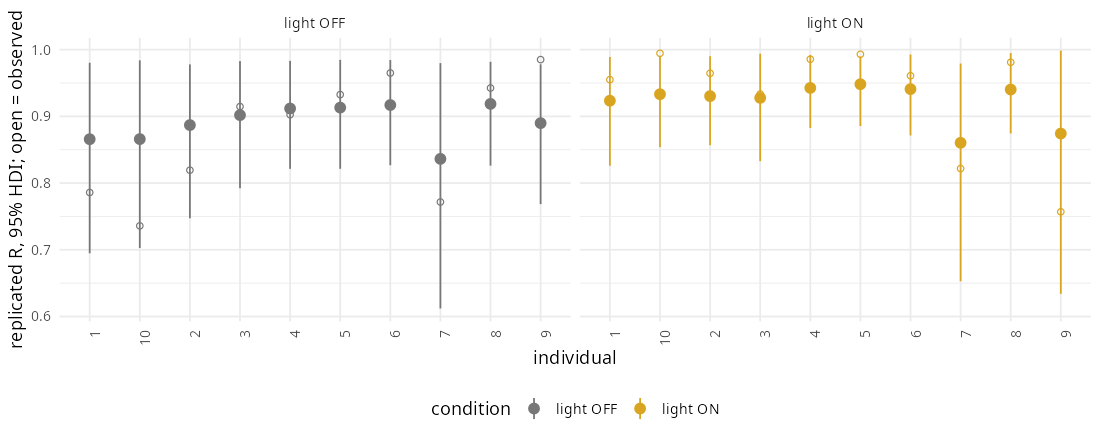

In [17]:
# Same observed sample sizes, each animal's own conditional likelihood.
# Limit simulation draws only; MCMC fitting still uses the budgets above.
set.seed(SEED + 20L)
draw_ids <- sample.int(nrow(mu), min(nrow(mu), if (quick_run) 100L else 400L))
rep_stats <- do.call(rbind, lapply(seq_along(ys), function(j) {
  rep_mu <- matrix(mu[draw_ids, j], nrow = length(draw_ids), ncol = length(ys[[j]]))
  rep_kappa <- matrix(kappa[draw_ids, j], nrow = length(draw_ids), ncol = length(ys[[j]]))
  yrep <- simulate_angles(rep_mu, rep_kappa)
  data.frame(id = as.character(prediction_data$Individual[j]),
    condition = prediction_data$condition[j],
    as.list(interval_row(apply(yrep, 1, resultant))),
    observed = resultant(ys[[j]]))
}))
p_replicates <- ggplot(rep_stats, aes(id, mean, colour = condition)) +
  geom_pointrange(aes(ymin = low, ymax = high)) +
  geom_point(aes(y = observed), shape = 1) +
  facet_wrap(~ condition) + scale_colour_manual(values = condition_colors) +
  labs(x = "individual", y = "replicated R, 95% HDI; open = observed") +
  theme(axis.text.x = element_text(angle = 90, hjust = 1),
        legend.position = "bottom")
save_figure(p_replicates, "ppc_replicated", 10, 4)
